# DeepNT+ experiments

Trains and evaluates the hybrid model on the dataset produced by `Dataset_Build.ipynb`, next to the baselines the
spec requires, with ablations, calibration and simulated active measurement scheduling.

**What DeepNT+ is here**

| Part | Implementation |
|---|---|
| Split-weight spatial GNN | `h' = ReLU(LN(W_s h + W_n mean_N h))`, structural node features plus a summary of the context measurements |
| Tomography layer | GNN predicts a non-negative delay per edge, path RTT `= A x + b` |
| Convex fusion | ridge tomography `min ||A x - y||^2 + a ||x - x0||^2` on the context paths (closed form), fused with the GNN path estimate by a learned per-path gate |
| Temporal branch | TGN node memory (GRU), then GRU + Transformer over the recent measurement history, strictly causal |
| Uncertainty | heteroscedastic Gaussian head, MC-dropout for epistemic variance |
| Active learning | variance and BALD acquisition, simulated by revealing real held-back measurements |

**Protocol.** Graph-level split (train 1-10, validation 11-12, test 13-15). At validation and test the model sees the RTT of the
*observed* paths only and predicts the *hidden* ones. RTT outliers are excluded everywhere. Packet loss has no labels in this
dataset, so no loss head is trained. Normalisation comes from the train graphs only.


In [20]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    THESIS = Path("/content/drive/My Drive/Thesis")
else:
    THESIS = Path(r"C:\Users\KINGDOM\Desktop\Thesis")
PROJECT_ROOT = THESIS / "DeepNT_Output"
PROCESSED = PROJECT_ROOT / "data" / "processed"

# the deepnt_plus package folder: in Colab copy it to  DeepNT_Output/code/deepnt_plus
candidates = [PROJECT_ROOT / "code", THESIS / "colab", Path.cwd(), Path.cwd().parent]
pkg_root = next((c for c in candidates if (c / "deepnt_plus" / "__init__.py").exists()), None)
if pkg_root is None:
    raise FileNotFoundError("deepnt_plus package not found. Copy the folder 'deepnt_plus' to "
                            f"{PROJECT_ROOT / 'code'} (searched: {[str(c) for c in candidates]})")
sys.path.insert(0, str(pkg_root))
REQUIRED_FILES = ["paths_all.csv", "path_ground_truth.csv", "node_features.csv", "edge_features.csv",
                  "tomography/A_graph_01.npz"]


def find_missing():
    return [f for f in REQUIRED_FILES if not (PROCESSED / f).exists()]


missing = find_missing()
if missing and IN_COLAB:
    # files added to Drive from outside this session (browser upload) are invisible to a stale mount
    print("files not visible, refreshing the Drive mount ...")
    drive.mount('/content/drive', force_remount=True)
    missing = find_missing()
if missing:
    seen = sorted(p.name for p in PROCESSED.parent.iterdir()) if PROCESSED.parent.exists() else "(folder does not exist)"
    seen_proc = sorted(p.name for p in PROCESSED.iterdir()) if PROCESSED.exists() else "(folder does not exist)"
    raise FileNotFoundError(f"missing in {PROCESSED}: {missing}\n"
                            f"this session sees data/: {seen}\nthis session sees data/processed/: {seen_proc}\n"
                            "If the files are in Drive but not listed here: Runtime > Disconnect and delete runtime, rerun, "
                            "and check the browser and Colab use the same Google account. Otherwise run Dataset_Build.ipynb.")
print("package:", pkg_root / "deepnt_plus", "\ndata   :", PROCESSED)


package: C:\Users\KINGDOM\Desktop\Thesis\colab\deepnt_plus 
data   : C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed


In [21]:
import pandas as pd
import torch

from deepnt_plus import active, report
from deepnt_plus.data import describe, load_dataset
from deepnt_plus.run import ABLATIONS, VARIANTS, run_all, summarise

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

SEEDS = (0, 1, 2)          # small data: report mean +- std over seeds
EPOCHS = 150
RUN_ABLATIONS = True
RUN_ACTIVE_LEARNING = True
FAST = False               # True = smaller model, for a quick smoke test
RUN_NAME = "run_02"      # run_01 = first run (monitor-confounded split), kept as a record
OUT_DIR = PROJECT_ROOT / "experiments" / "deepnt" / RUN_NAME

graphs, norm = load_dataset(PROCESSED)
overview = describe(graphs)
print(overview.to_string(index=False))
n_tr = overview[overview.split == "train"]
print(f"\ntrain graphs: {int(n_tr.paths.sum())} paths ({int(n_tr.observed.sum())} observed) | "
      f"val hidden paths: {int(overview[overview.split == 'val'].hidden.sum())} | "
      f"test hidden paths: {int(overview[overview.split == 'test'].hidden.sum())}")
print(f"PyTorch {torch.__version__} | packet-loss labels present: "
      f"{bool(any((~torch.isnan(g.loss)).any() for g in graphs.values()))}")


   graph split  nodes  edges  paths  observed  hidden  outliers  median_rtt_ms
graph_01 train    414    419     89        27      62         0     133.330002
graph_02 train    339    346     89        27      62         0     111.192001
graph_03 train    405    411     89        27      62         0     111.599998
graph_04 train    498    500     89        27      62         0      60.292999
graph_05 train    439    443     89        27      62         0      45.752998
graph_06 train    514    530     89        27      62         0     206.781006
graph_07 train    506    514     88        26      62         0     205.535995
graph_08 train    490    495     88        26      62         0     198.723007
graph_09 train    490    495     88        26      62         0     208.138000
graph_10 train    449    453     88        26      62         0     148.136002
graph_11   val    377    397     88        26      62         0     176.298996
graph_12   val    274    288     88        26      6

In [22]:
gt = pd.read_csv(PROCESSED / "path_ground_truth.csv")
flagged = gt[gt["quality_flag"].astype(str).str.contains("rtt_outlier")]
print(f"{len(flagged)} of {len(gt)} paths are flagged as RTT outliers and left out of context, training and metrics "
      f"(rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:")
print(flagged[["path_id", "graph_id", "split", "rtt_ms", "quality_flag"]].round(1).to_string(index=False) if len(flagged) else "none")
print("\nmonitors per split:")
paths_all = pd.read_csv(PROCESSED / "paths_all.csv")
print(paths_all.groupby(["split", "monitor_id"]).size().unstack(fill_value=0).to_string())


0 of 1326 paths are flagged as RTT outliers and left out of context, training and metrics (rule from Dataset_Build: RTT outside [0.05, 1000] ms). They stay in the dataset files:
none

monitors per split:
monitor_id  abz2-uk  acc-gh  dac-bd
split                              
test              0       0     264
train           431     417      38
val               0       0     176


## Train and evaluate everything

Baselines (median, hop-count, LR, RF, MLP, classical convex tomography), GraphSAGE, GAT, DeepNT (static), DeepNT+ (full) and the
ablations, over several seeds. Writes `predictions.csv`, `metrics_summary.csv`, `history.csv`, `config.json` and the checkpoints
to `experiments/deepnt/<run>/`.

In [23]:
pred, summary = run_all(PROCESSED, OUT_DIR, seeds=SEEDS, epochs=EPOCHS, ablations=RUN_ABLATIONS,
                        active_learning=RUN_ACTIVE_LEARNING, fast=FAST)
print("saved to", OUT_DIR)


15 graphs | packet-loss labels available: False
--- GraphSAGE | seed 0
epoch   1 | train loss 0.9630 | val MAE 66.55 ms
epoch  10 | train loss 0.5755 | val MAE 58.30 ms
epoch  20 | train loss 0.3408 | val MAE 62.00 ms
epoch  30 | train loss 0.4341 | val MAE 71.36 ms
--- GraphSAGE | seed 1
epoch   1 | train loss 1.0124 | val MAE 64.73 ms
epoch  10 | train loss 0.6583 | val MAE 59.01 ms
epoch  20 | train loss 0.3897 | val MAE 62.96 ms
--- GraphSAGE | seed 2
epoch   1 | train loss 1.0118 | val MAE 66.29 ms
epoch  10 | train loss 0.4909 | val MAE 52.22 ms
epoch  20 | train loss 0.4182 | val MAE 56.49 ms
--- GAT | seed 0
epoch   1 | train loss 0.9589 | val MAE 65.82 ms
epoch  10 | train loss 0.6491 | val MAE 52.33 ms
epoch  20 | train loss 0.3218 | val MAE 61.61 ms
--- GAT | seed 1
epoch   1 | train loss 1.0130 | val MAE 66.02 ms
epoch  10 | train loss 0.6816 | val MAE 81.85 ms
epoch  20 | train loss 0.3568 | val MAE 56.82 ms
epoch  30 | train loss 0.3478 | val MAE 59.29 ms
epoch  40 | trai

C:\Users\KINGDOM\Desktop\Thesis\colab\deepnt_plus\baselines.py:24: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  rows.append(np.concatenate([[g.hops[p], np.log1p(g.hops[p])], nf.mean(0), nf.max(0), nf.min(0),


saved to C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\run_02


## Results on the hidden paths

Test graphs are scored once; validation graphs chose each checkpoint. `MAE`, `RMSE`, `MedAE` are in ms.

In [30]:
cols = ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean", "RMSE_mean", "R2_mean", "n_mean"]
cols = [c for c in cols if c in summary.columns]
for split in ("test", "val"):
    print(f"=== {split} graphs ===")
    print(summary[summary.split == split][cols].sort_values("MAE_mean").round(3).to_string(index=False))


=== test graphs ===
                           model  MAE_mean  MAE_std  MedAE_mean  RMSE_mean  R2_mean  n_mean
   Convex tomography (classical)    59.555      NaN      31.394    200.634    0.047   186.0
                 DeepNT (static)    65.676    4.429      42.243    202.726    0.027   186.0
                  DeepNT+ (full)    74.105    1.707      46.999    207.220   -0.017   186.0
         DeepNT (static, causal)    74.207    2.735      46.055    206.976   -0.014   186.0
       DeepNT+ - temporal branch    77.002    4.519      50.556    208.367   -0.028   186.0
DeepNT+ - uncertainty (MSE only)    80.625    9.127      54.314    209.520   -0.040   186.0
      DeepNT+ - context features    81.112    5.861      55.817    210.199   -0.046   186.0
         DeepNT+ - convex fusion    84.376    6.911      56.533    210.702   -0.052   186.0
                             GAT    90.341    3.134      74.140    211.899   -0.063   186.0
                       GraphSAGE    91.102    5.741      75.

## Does each component earn its place?

Ablations remove one part of DeepNT+ (full). `delta_MAE` is the change against the full model, so a positive value means the part helps.
Read it next to `MAE_std`: with this little data, differences smaller than the seed-to-seed spread are not evidence.

In [31]:
test = summary[summary.split == "test"].set_index("model")
full = "DeepNT+ (full)"
if full in test.index:
    names = [n for n in list(ABLATIONS) + ["DeepNT (static, causal)", "DeepNT (static)", "GraphSAGE", "GAT"] if n in test.index]
    table = test.loc[names, ["MAE_mean", "MAE_std"]].copy()
    table["delta_MAE_vs_full"] = table["MAE_mean"] - test.loc[full, "MAE_mean"]
    table["larger_than_seed_spread"] = table["delta_MAE_vs_full"].abs() > (table["MAE_std"].fillna(0) + test.loc[full, "MAE_std"])
    print(f"{full}: MAE {test.loc[full, 'MAE_mean']:.3f} +- {test.loc[full, 'MAE_std']:.3f} ms\n")
    print(table.round(3).to_string())


DeepNT+ (full): MAE 74.105 +- 1.707 ms

                                  MAE_mean  MAE_std  delta_MAE_vs_full  larger_than_seed_spread
model                                                                                          
DeepNT+ - temporal branch           77.002    4.519              2.897                    False
DeepNT+ - convex fusion             84.376    6.911             10.271                     True
DeepNT+ - tomography layer         105.303   10.700             31.198                     True
DeepNT+ - uncertainty (MSE only)    80.625    9.127              6.520                    False
DeepNT+ - context features          81.112    5.861              7.007                    False
DeepNT (static, causal)             74.207    2.735              0.102                    False
DeepNT (static)                     65.676    4.429             -8.429                     True
GraphSAGE                           91.102    5.741             16.997                     True


## Uncertainty calibration

`coverage_90` is the share of hidden paths whose true RTT falls inside the 90% predictive interval (ideal 0.90). `ECE_reg` is the mean
gap between nominal and empirical coverage over 50/80/90/95% (0 is perfect). `NLL` is in log-RTT space.

In [32]:
cal_cols = [c for c in ["model", "NLL_mean", "sharpness_log_mean", "coverage_50_mean", "coverage_80_mean",
                        "coverage_90_mean", "coverage_95_mean", "ECE_reg_mean"] if c in summary.columns]
print(summary[(summary.split == "test") & summary["ECE_reg_mean"].notna()][cal_cols].sort_values("ECE_reg_mean").round(3).to_string(index=False))


                           model  NLL_mean  sharpness_log_mean  coverage_50_mean  coverage_80_mean  coverage_90_mean  coverage_95_mean  ECE_reg_mean
         DeepNT (static, causal)     0.679               0.349             0.498             0.780             0.876             0.914         0.053
                 DeepNT (static)     0.781               0.243             0.437             0.719             0.842             0.889         0.066
       DeepNT+ - temporal branch     0.776               0.325             0.450             0.710             0.832             0.892         0.067
                  DeepNT+ (full)     0.762               0.299             0.441             0.722             0.824             0.871         0.073
         DeepNT+ - convex fusion     0.822               0.340             0.394             0.672             0.839             0.884         0.090
      DeepNT+ - tomography layer     0.943               0.443             0.271             0.686        

## Active measurement scheduling (simulated)

On each test graph a quarter of the hidden paths is held out for scoring. Every round the strategy picks paths from the rest, their
real stored RTT is revealed to the model, and MAE is re-measured on the held-out paths. Lower curves mean better use of the probe budget.

In [33]:
ac_file = OUT_DIR / "active_learning.csv"
if ac_file.exists():
    curves = pd.read_csv(ac_file)
    mean_curve, auc = active.summarise(curves)
    print(auc.round(3).to_string(index=False))
    print("\n(mean MAE over rounds; 'random' is the reference every scheduler must beat)")
else:
    print("active learning was not run")


     strategy  mean_MAE_over_rounds
         bald                46.300
       random                46.932
     variance                49.386
edge_coverage                49.447
 longest_path                49.472

(mean MAE over rounds; 'random' is the reference every scheduler must beat)


## Figures

loss_curve.png


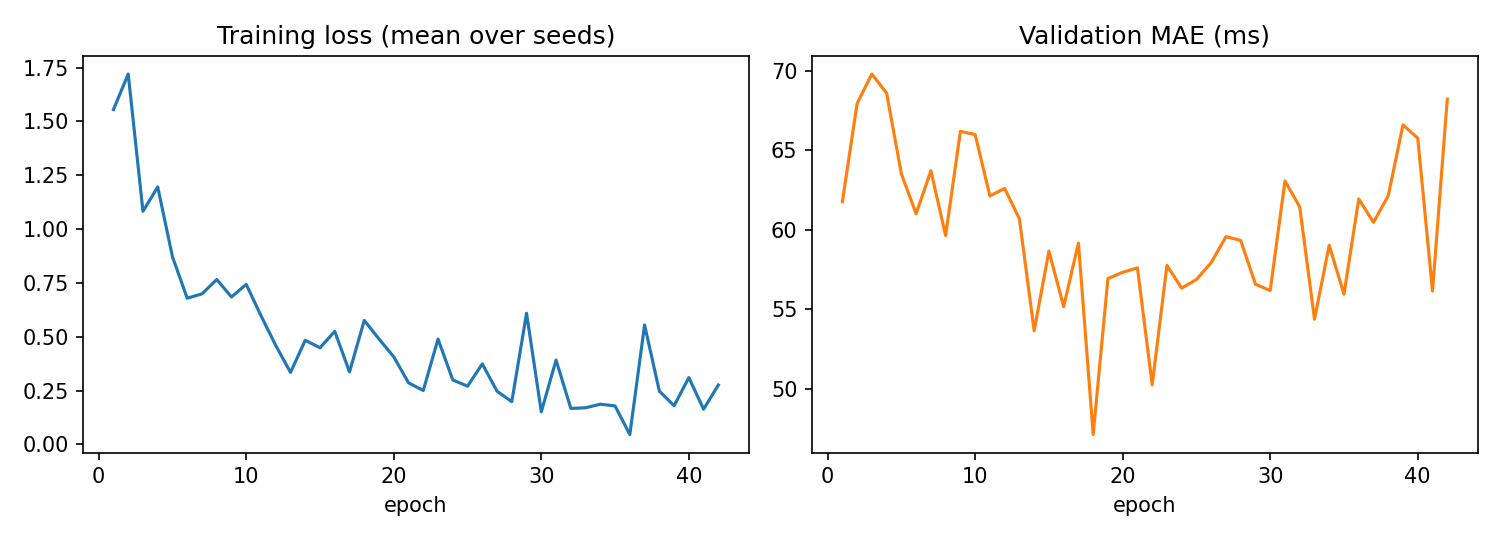

delay_prediction.png


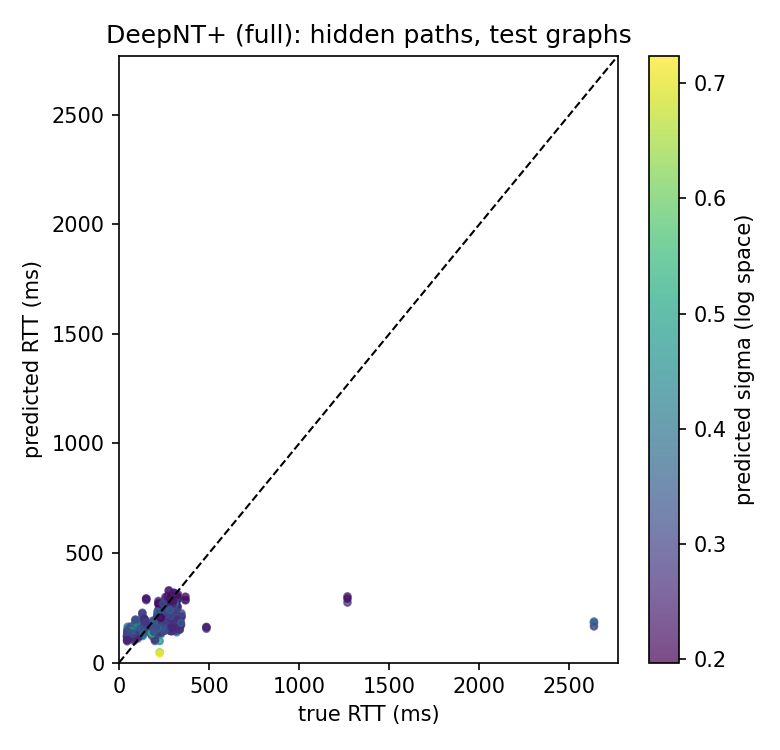

calibration.png


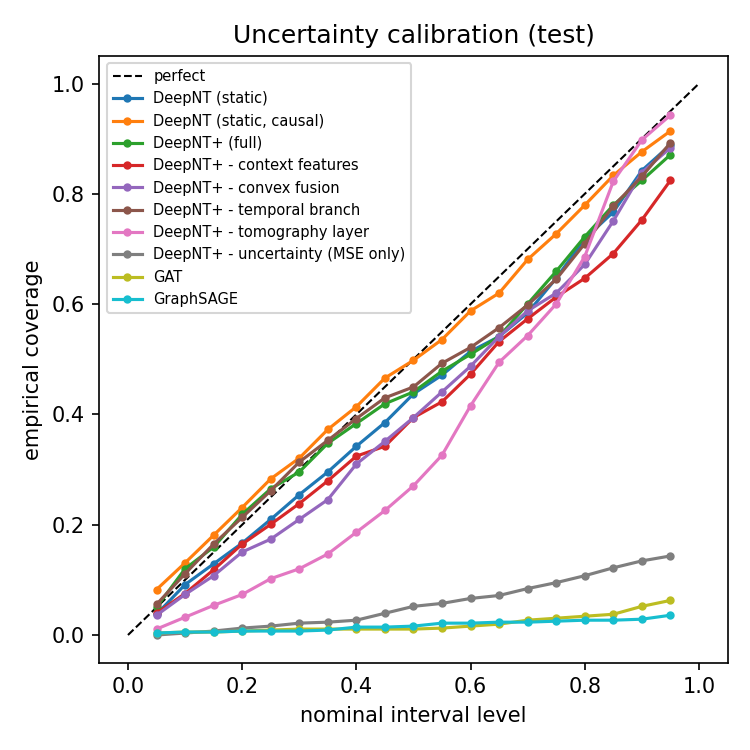

model_comparison.png


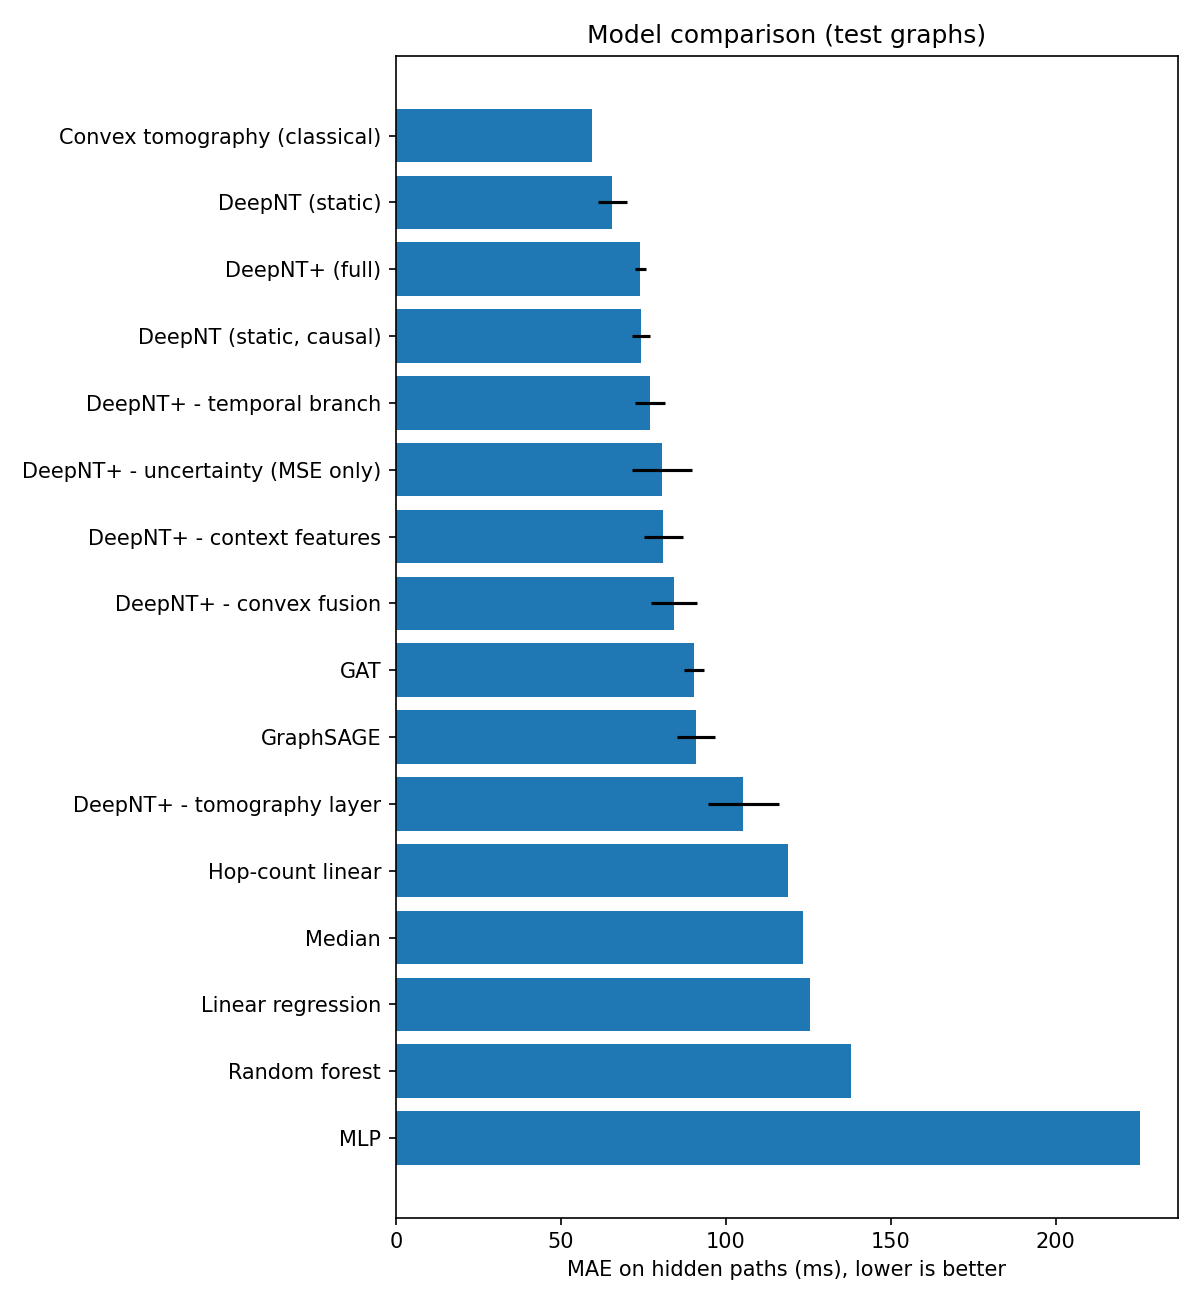

active_learning.png


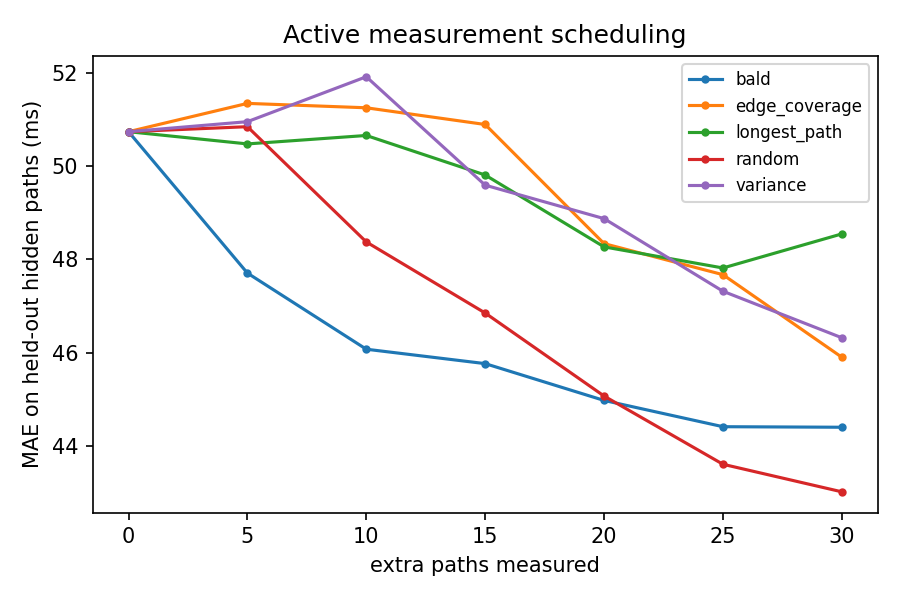

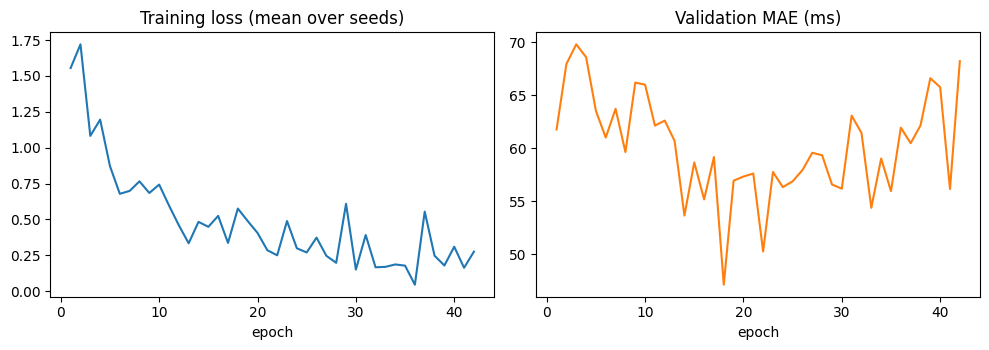

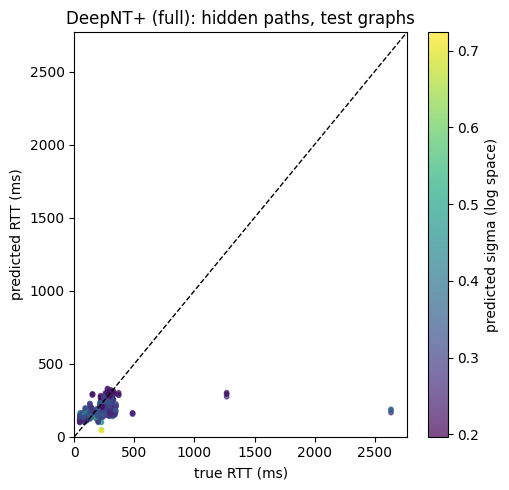

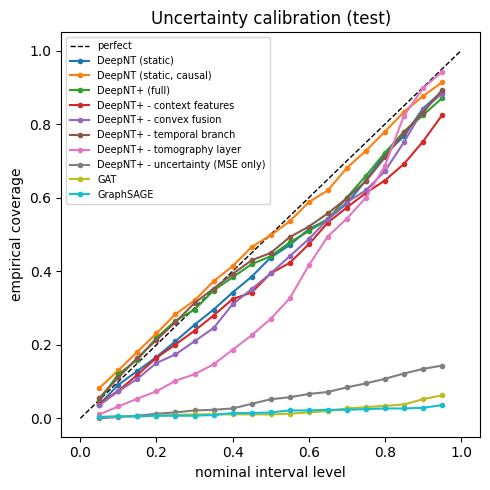

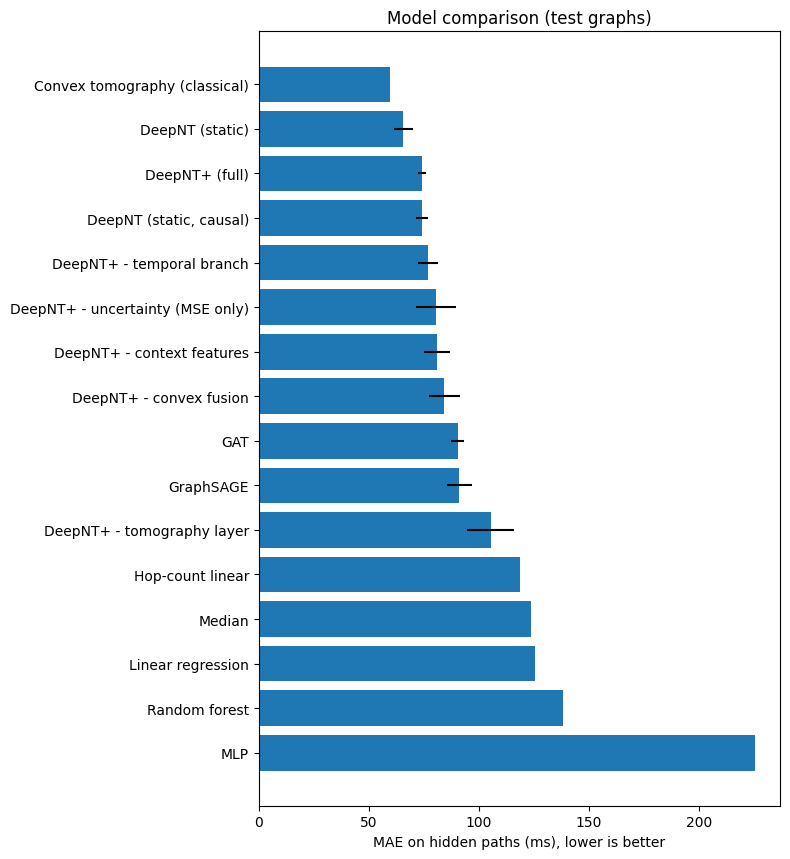

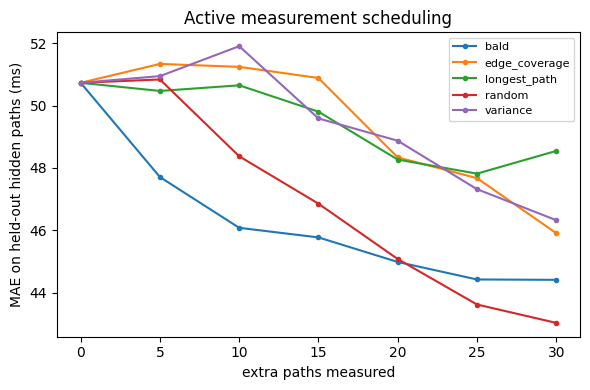

In [34]:
from IPython.display import Image, display
for f in report.make_all(OUT_DIR):
    print(f.name)
    display(Image(filename=str(f)))


## Cross-vantage-point test (optional)

Set `HOLDOUT_MONITOR` to one Ark monitor (for example `"dac-bd"`). Every graph dominated by that monitor becomes a test graph and the
model trains only on the other monitors. This is a much harder question than the standard split: does the model transfer to a vantage
point it has never seen? Expect worse numbers and read them as a robustness result.

In [35]:
HOLDOUT_MONITOR = None        # e.g. "dac-bd"
if HOLDOUT_MONITOR:
    hold_dir = OUT_DIR.parent / f"{RUN_NAME}_holdout_{HOLDOUT_MONITOR}"
    _, hold_summary = run_all(PROCESSED, hold_dir, seeds=SEEDS, epochs=EPOCHS, variants=["GraphSAGE", "DeepNT (static)"],
                              ablations=False, active_learning=False, fast=FAST, holdout_monitor=HOLDOUT_MONITOR)
    hc = [c for c in ["model", "MAE_mean", "MAE_std", "MedAE_mean", "MdAPE_mean", "MAE_log_mean"] if c in hold_summary.columns]
    print(f"test = graphs dominated by {HOLDOUT_MONITOR}; results saved to {hold_dir}")
    print(hold_summary[hold_summary.split == "test"][hc].sort_values("MAE_mean").round(3).to_string(index=False))
else:
    print("set HOLDOUT_MONITOR to run the cross-vantage-point test")


set HOLDOUT_MONITOR to run the cross-vantage-point test


## How to read these results

- **Claims you can make:** the model predicts the RTT of hidden paths on unseen graphs; how far it beats the baselines; how well its uncertainty is
  calibrated; which components matter (only where the ablation gap exceeds the seed spread); whether uncertainty-driven measurement scheduling beats random.
- **Claims you cannot make yet:** anything about packet loss (no labels), long-horizon temporal dynamics (the measurements cover about two days and
  almost no path repeats), or comparisons with RIPE Atlas or EvolveGCN (not in this dataset / not implemented).
- **Where the temporal branch can help:** only if RTT drifts within the two days. If `DeepNT+ (full)` does not beat `DeepNT (static, causal)` by more
  than the seed spread, report that honestly: it is a legitimate finding about this data, not a bug.
